## 1. Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pathlib import Path

# Thiết lập cấu hình đồ thị báo cáo
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.autolayout'] = True

In [2]:
# Cấu hình thư mục
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Đường dẫn đọc dữ liệu thô và xuất dữ liệu sạch
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "data2026.csv"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
CLEAN_DATA_PATH = PROCESSED_DATA_DIR / "weather_clean.csv"

# Tự động tạo thư mục nếu chưa tồn tại
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Thư mục gốc dự án:", PROJECT_ROOT)
print("Đường dẫn file dữ liệu thô:", RAW_DATA_PATH)
print("Đường dẫn lưu dữ liệu sạch:", CLEAN_DATA_PATH)

Thư mục gốc dự án: /Users/tuong/Documents/MONHOCDAIHOC/năm IV-HK1 (2026-2027)/PP Nghiên Cứu KHDL/Frankfurt_Temperature_Forecasting
Đường dẫn file dữ liệu thô: /Users/tuong/Documents/MONHOCDAIHOC/năm IV-HK1 (2026-2027)/PP Nghiên Cứu KHDL/Frankfurt_Temperature_Forecasting/data/raw/data2026.csv
Đường dẫn lưu dữ liệu sạch: /Users/tuong/Documents/MONHOCDAIHOC/năm IV-HK1 (2026-2027)/PP Nghiên Cứu KHDL/Frankfurt_Temperature_Forecasting/data/processed/weather_clean.csv


## 2. Đọc dữ liệu & Khảo sát cấu trúc ban đầu

In [3]:
# Đọc file dữ liệu khí tượng quan trắc tại trạm Frankfurt Airport
df_raw = pd.read_csv(RAW_DATA_PATH)

print(f"Kích thước dữ liệu thô: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột.")
print("\n5 dòng đầu tiên:")
display(df_raw.head())

print("\nThông tin kiểu dữ liệu (Data types):")
df_raw.info()

df_raw['date'] = pd.to_datetime(df_raw['date'])
# split: train 2020–2024 | val 2025 | test 01/01–30/06/2026
df_raw['split'] = np.select(
    [df_raw['date'] <= '2024-12-31', df_raw['date'] <= '2025-12-31'],
    ['train', 'val'], default='test')
print("\nSố ngày theo từng tập:")
print(df_raw['split'].value_counts().reindex(['train', 'val', 'test']))

Kích thước dữ liệu thô: 2373 dòng, 11 cột.

5 dòng đầu tiên:


,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,2020-01-01 00:00:00,0.4,-3.6,4.5,0.1,0,NaN,10.1,22.3,1035.5,438
1,2020-01-02 00:00:00,-0.5,-2.4,1.4,0.0,0,NaN,6.1,25.9,1031.2,0
2,2020-01-03 00:00:00,5.8,1.3,9.3,0.5,0,NaN,15.5,46.8,1024.4,0
3,2020-01-04 00:00:00,5.4,2.4,6.8,0.2,0,NaN,15.8,47.5,1031.5,0
4,2020-01-05 00:00:00,4.8,2.7,6.3,1.1,0,NaN,6.8,23.4,1036.6,0



Thông tin kiểu dữ liệu (Data types):
<class 'pandas.DataFrame'>
RangeIndex: 2373 entries, 0 to 2372
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    2373 non-null   str    
 1   tavg    2373 non-null   float64
 2   tmin    2373 non-null   float64
 3   tmax    2373 non-null   float64
 4   prcp    2373 non-null   float64
 5   snow    2373 non-null   int64  
 6   wdir    0 non-null      float64
 7   wspd    2373 non-null   float64
 8   wpgt    2373 non-null   float64
 9   pres    2373 non-null   float64
 10  tsun    2373 non-null   int64  
dtypes: float64(8), int64(2), str(1)
memory usage: 204.1 KB

Số ngày theo từng tập:
split
train    1827
val       365
test      181
Name: count, dtype: int64


## 3. Kiểm toán dữ liệu thời gian & Giá trị khuyết thiếu

In [4]:
# 1. Ép kiểu cột date sang datetime và thiết lập DatetimeIndex
df_raw['date'] = pd.to_datetime(df_raw['date'])
df_time = df_raw.sort_values('date').set_index('date')

# Kiểm tra ngày trùng lặp và thứ tự thời gian
so_ngay_trung = df_time.index.duplicated().sum()
print(f"Số ngày bị trùng lặp: {so_ngay_trung}")
print(f"Chỉ mục thời gian tăng dần: {df_time.index.is_monotonic_increasing}")
assert so_ngay_trung == 0, "Cảnh báo: Có ngày bị trùng lặp trong dữ liệu!"

print("--- KIỂM TOÁN TÍNH LIÊN TỤC TRỤC THỜI GIAN ---")
print(f"Khoảng thời gian quan trắc: từ {df_time.index.min().strftime('%Y-%m-%d')} đến {df_time.index.max().strftime('%Y-%m-%d')}")
print(f"Tổng số ngày quan sát thực tế: {len(df_time)} ngày")

# Kiểm tra xem có ngày nào bị gián đoạn/thiếu trong toàn dải không
expected_dates = pd.date_range(start=df_time.index.min(), end=df_time.index.max(), freq='D')
missing_dates = expected_dates.difference(df_time.index)
print(f"Số ngày bị gián đoạn trên trục thời gian: {len(missing_dates)}")

# 2. Thống kê chi tiết missing values trên từng thuộc tính
missing_summary = pd.DataFrame({
    'Số lượng rỗng': df_time.isnull().sum(),
    'Tỷ lệ rỗng (%)': (df_time.isnull().sum() / len(df_time) * 100).round(2)
})
print("\n--- BẢNG THỐNG KÊ GIÁ TRỊ KHUYẾT THIẾU BAN ĐẦU ---")
display(missing_summary)

Số ngày bị trùng lặp: 0
Chỉ mục thời gian tăng dần: True
--- KIỂM TOÁN TÍNH LIÊN TỤC TRỤC THỜI GIAN ---
Khoảng thời gian quan trắc: từ 2020-01-01 đến 2026-06-30
Tổng số ngày quan sát thực tế: 2373 ngày
Số ngày bị gián đoạn trên trục thời gian: 0

--- BẢNG THỐNG KÊ GIÁ TRỊ KHUYẾT THIẾU BAN ĐẦU ---


,Số lượng rỗng,Tỷ lệ rỗng (%)
tavg,0,0.0
tmin,0,0.0
tmax,0,0.0
prcp,0,0.0
snow,0,0.0
wdir,2373,100.0
wspd,0,0.0
wpgt,0,0.0
pres,0,0.0
tsun,0,0.0


## 4. Tiền xử lý dữ liệu & Loại bỏ cột

In [5]:
df_clean = df_time.drop(columns=['wdir']).copy()

# Thiết lập tần suất hàng ngày cố định (Daily frequency - 'D')
df_clean = df_clean.asfreq('D')

# Kiểm tra lại sau tiền xử lý
total_null = df_clean.isnull().sum().sum()
print(f"Số cột hiện tại: {df_clean.shape[1]}")
print(f"Tổng số giá trị khuyết thiếu còn lại: {total_null}")
assert total_null == 0, "Cảnh báo: Vẫn còn missing values tồn tại trong dữ liệu!"
print("-> Toàn bộ dữ liệu sạch và sẵn sàng cho phân tích EDA.")
assert df_clean.index.freq == 'D' and df_clean.index.is_unique
assert df_clean['tavg'].notna().all()

# EDA chỉ trên train + val (2020–2025); tập test (2026) không phân tích
df_eda = df_clean[df_clean['split'] != 'test'].copy()
print(f"Tập EDA: {df_eda.index.min():%Y-%m-%d} -> {df_eda.index.max():%Y-%m-%d} ({len(df_eda)} ngày)")

Số cột hiện tại: 10
Tổng số giá trị khuyết thiếu còn lại: 0
-> Toàn bộ dữ liệu sạch và sẵn sàng cho phân tích EDA.
Tập EDA: 2020-01-01 -> 2025-12-31 (2192 ngày)


## 5. Tổng quan toàn bộ các biến

,Ý nghĩa,Đơn vị
tavg,Nhiệt độ trung bình ngày,°C
tmin,Nhiệt độ tối thiểu ngày,°C
tmax,Nhiệt độ tối đa ngày,°C
prcp,Tổng lượng mưa ngày,mm
snow,Độ sâu lớp tuyết,mm
wspd,Tốc độ gió trung bình,km/h
wpgt,Gió giật cực đại,km/h
pres,Áp suất quy về mực nước biển,hPa
tsun,Tổng thời gian nắng,phút


,count,mean,std,min,25%,50%,75%,max
tavg,2192.0,11.96,7.22,-7.8,6.20,11.60,17.90,30.1
tmin,2192.0,7.03,6.37,-11.5,2.00,6.95,12.30,22.6
tmax,2192.0,16.73,8.65,-5.5,9.98,16.40,23.80,38.4
prcp,2192.0,1.75,3.96,0.0,0.00,0.00,1.52,62.5
snow,2192.0,0.25,2.68,0.0,0.00,0.00,0.00,60.0
wspd,2192.0,12.40,5.79,3.2,8.30,10.80,15.50,39.6
wpgt,2192.0,38.01,13.58,12.6,28.80,36.40,45.00,126.0
pres,2192.0,1017.95,8.89,981.7,1012.90,1018.10,1023.50,1047.5
tsun,2192.0,318.65,284.89,0.0,42.00,252.00,558.00,942.0


,Tỷ lệ ngày bằng 0 (%)
prcp,55.7
snow,98.9
tsun,16.6


Số ngày vi phạm tmin <= tavg <= tmax: 0


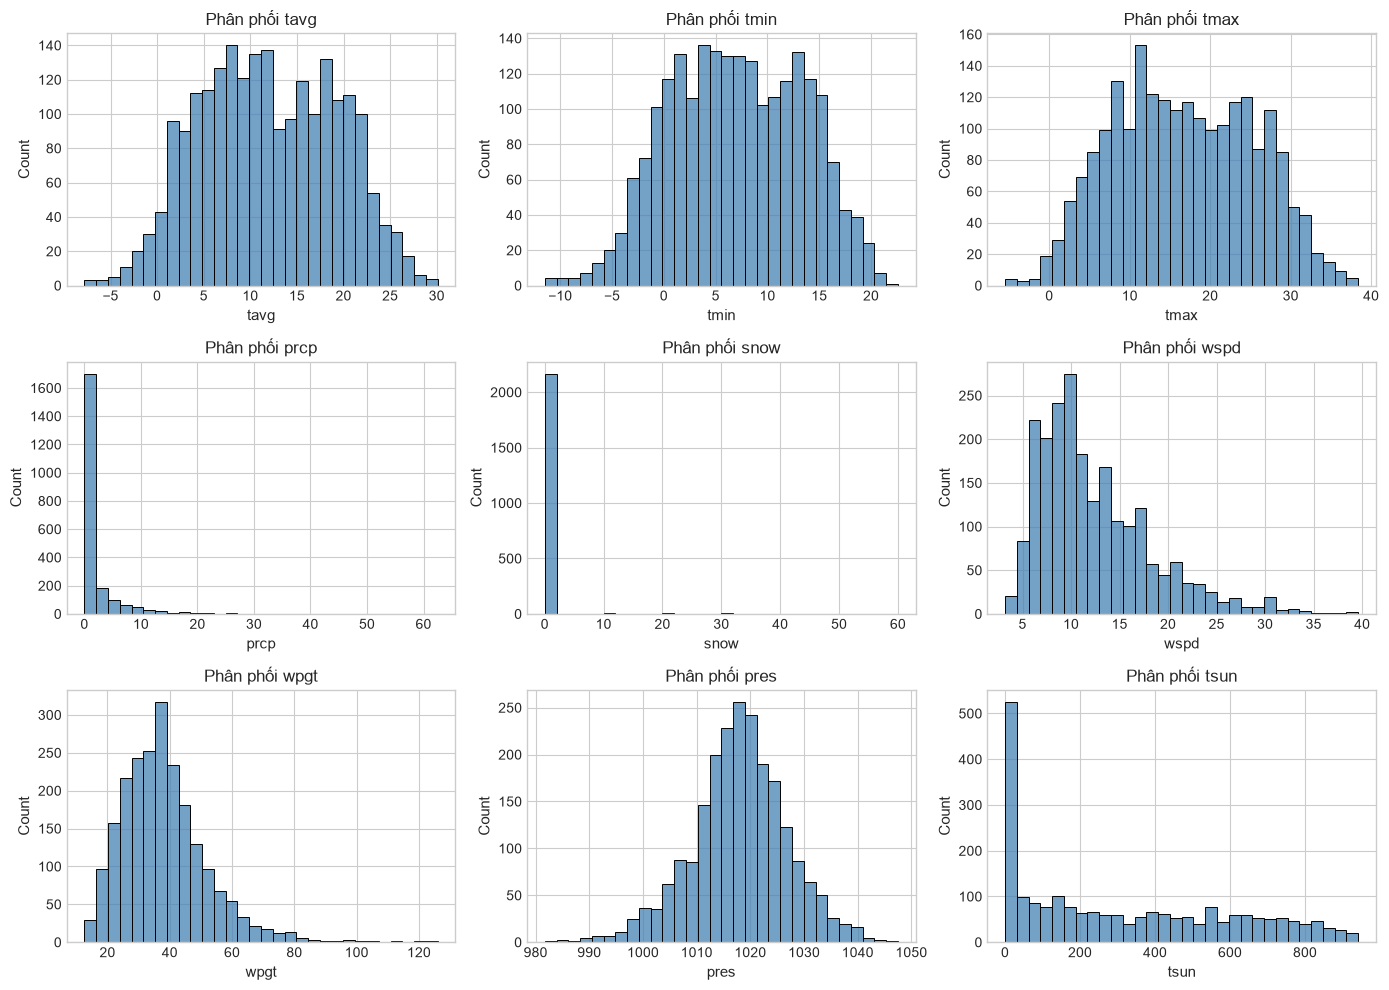

In [6]:
mo_ta_bien = pd.DataFrame({
    'Ý nghĩa': ['Nhiệt độ trung bình ngày', 'Nhiệt độ tối thiểu ngày', 'Nhiệt độ tối đa ngày',
                'Tổng lượng mưa ngày', 'Độ sâu lớp tuyết', 'Tốc độ gió trung bình',
                'Gió giật cực đại', 'Áp suất quy về mực nước biển', 'Tổng thời gian nắng'],
    'Đơn vị': ['°C', '°C', '°C', 'mm', 'mm', 'km/h', 'km/h', 'hPa', 'phút']},
    index=['tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wspd', 'wpgt', 'pres', 'tsun'])
display(mo_ta_bien)
cot_so = ['tavg','tmin','tmax','prcp','snow','wspd','wpgt','pres','tsun']
display(df_eda[cot_so].describe().T.round(2))

ty_le_0 = (df_eda[['prcp','snow','tsun']] == 0).mean().mul(100).round(1)
display(ty_le_0.to_frame('Tỷ lệ ngày bằng 0 (%)'))
print("Số ngày vi phạm tmin <= tavg <= tmax:",
      ((df_eda['tavg'] < df_eda['tmin']) | (df_eda['tavg'] > df_eda['tmax'])).sum())

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, c in zip(axes.ravel(), cot_so):
    sns.histplot(df_eda[c], bins=30, color='steelblue', ax=ax)
    ax.set_title(f'Phân phối {c}')
plt.show()

## 6. Ma trận tương quan

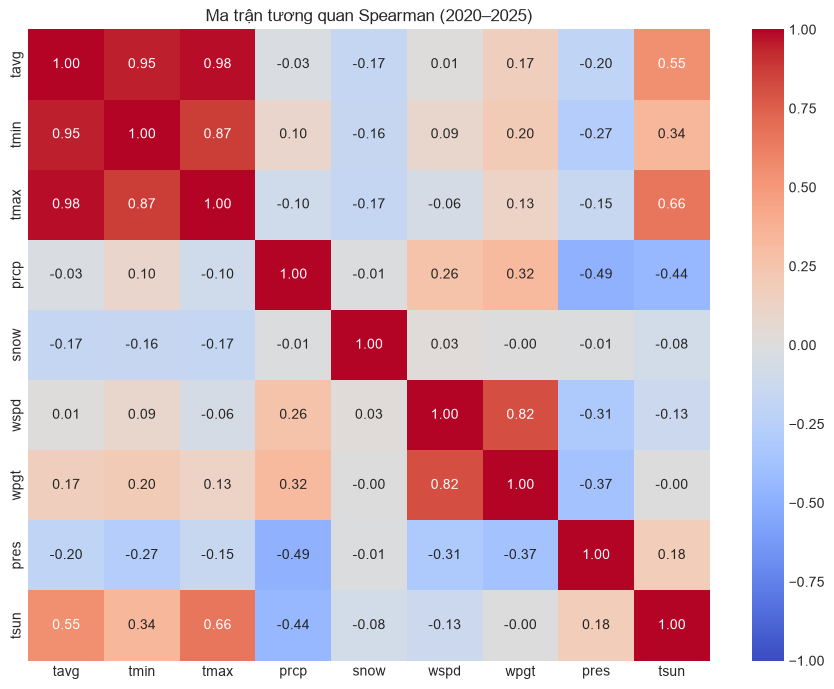

In [7]:
tuong_quan = df_eda[cot_so].corr(method='spearman').round(2)
plt.figure(figsize=(9, 7))
sns.heatmap(tuong_quan, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Ma trận tương quan Spearman (2020–2025)')
plt.show()

## 7. Thống kê mô tả & Phân phối biến mục tiêu

--- BẢNG THỐNG KÊ MÔ TẢ NHIỆT ĐỘ TAVG (GIAI ĐOẠN 2020–2025) ---


,Giá trị (°C)
Số quan sát (Count),2192.000000
Trung bình (Mean),11.958759
Độ lệch chuẩn (Std),7.222996
Trung vị (Median),11.600000
Giá trị nhỏ nhất (Min),-7.800000
Phân vị 25% (Q1),6.200000
Phân vị 75% (Q3),17.900000
Khoảng trải giữa (IQR),11.700000
Giá trị lớn nhất (Max),30.100000
Hệ số bất đối xứng (Skewness),0.021340


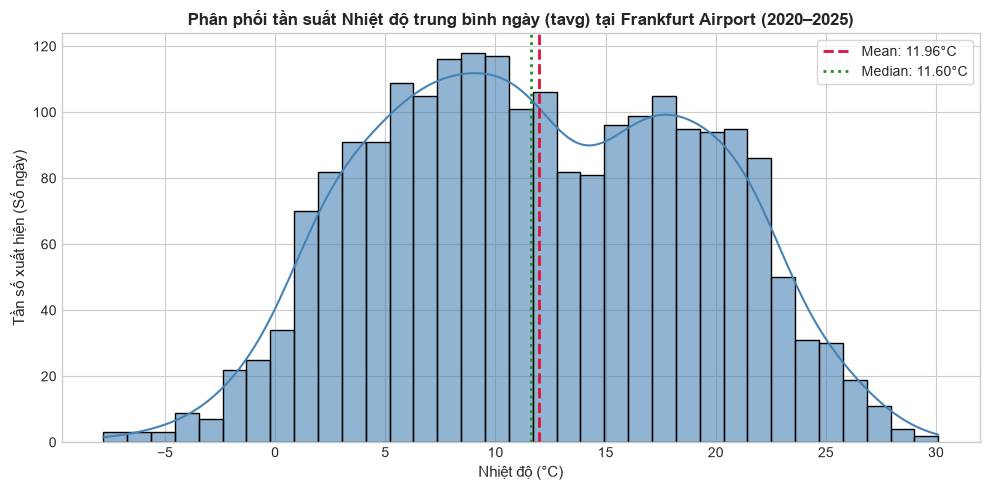

Nhận định: phân phối đối xứng (skew = 0.02) và phẳng hơn chuẩn (platykurtic) (kurtosis = -0.82); độ phẳng phản ánh cấu trúc hai mùa rõ rệt, không phải phân phối chuẩn.


In [8]:
# Phân tích biến mục tiêu tavg trong phạm vi nghiên cứu RQ1 (2020–2025)
tavg_rq1 = df_eda['tavg']

desc = tavg_rq1.describe()
skewness = tavg_rq1.skew()
kurtosis = tavg_rq1.kurtosis()
iqr = desc['75%'] - desc['25%']

desc_stats = pd.Series({
    'Số quan sát (Count)': int(desc['count']),
    'Trung bình (Mean)': desc['mean'],
    'Độ lệch chuẩn (Std)': desc['std'],
    'Trung vị (Median)': desc['50%'],
    'Giá trị nhỏ nhất (Min)': desc['min'],
    'Phân vị 25% (Q1)': desc['25%'],
    'Phân vị 75% (Q3)': desc['75%'],
    'Khoảng trải giữa (IQR)': iqr,
    'Giá trị lớn nhất (Max)': desc['max'],
    'Hệ số bất đối xứng (Skewness)': skewness,
    'Độ nhọn (Kurtosis)': kurtosis
})

print("--- BẢNG THỐNG KÊ MÔ TẢ NHIỆT ĐỘ TAVG (GIAI ĐOẠN 2020–2025) ---")
display(desc_stats.to_frame(name='Giá trị (°C)'))

# Vẽ Histogram và đường KDE
plt.figure(figsize=(10, 5))
sns.histplot(tavg_rq1, kde=True, bins=35, color='steelblue', edgecolor='black', alpha=0.6)
plt.axvline(desc['mean'], color='crimson', linestyle='--', linewidth=2, label=f"Mean: {desc['mean']:.2f}°C")
plt.axvline(desc['50%'], color='forestgreen', linestyle=':', linewidth=2, label=f"Median: {desc['50%']:.2f}°C")

plt.title('Phân phối tần suất Nhiệt độ trung bình ngày (tavg) tại Frankfurt Airport (2020–2025)', fontsize=12, fontweight='bold')
plt.xlabel('Nhiệt độ (°C)')
plt.ylabel('Tần số xuất hiện (Số ngày)')
plt.legend(frameon=True)
plt.show()

dang = 'đối xứng' if abs(skewness) < 0.5 else 'lệch'
do_nhon = 'phẳng hơn chuẩn (platykurtic)' if kurtosis < 0 else 'nhọn hơn chuẩn'
print(f"Nhận định: phân phối {dang} (skew = {skewness:.2f}) và {do_nhon} (kurtosis = {kurtosis:.2f}); "
      "độ phẳng phản ánh cấu trúc hai mùa rõ rệt, không phải phân phối chuẩn.")


## 8. Khảo sát ngoại lệ theo từng tháng & Giữ nguyên cực trị

--- THỐNG KÊ GIÁ TRỊ CỰC TRỊ (2020–2025) ---
- Thấp nhất: -7.8°C (ngày 17/12/2022)
- Cao nhất: 30.1°C (ngày 04/08/2022)
- Số ngày có tavg < -5°C (ngưỡng rét sâu): 6 ngày


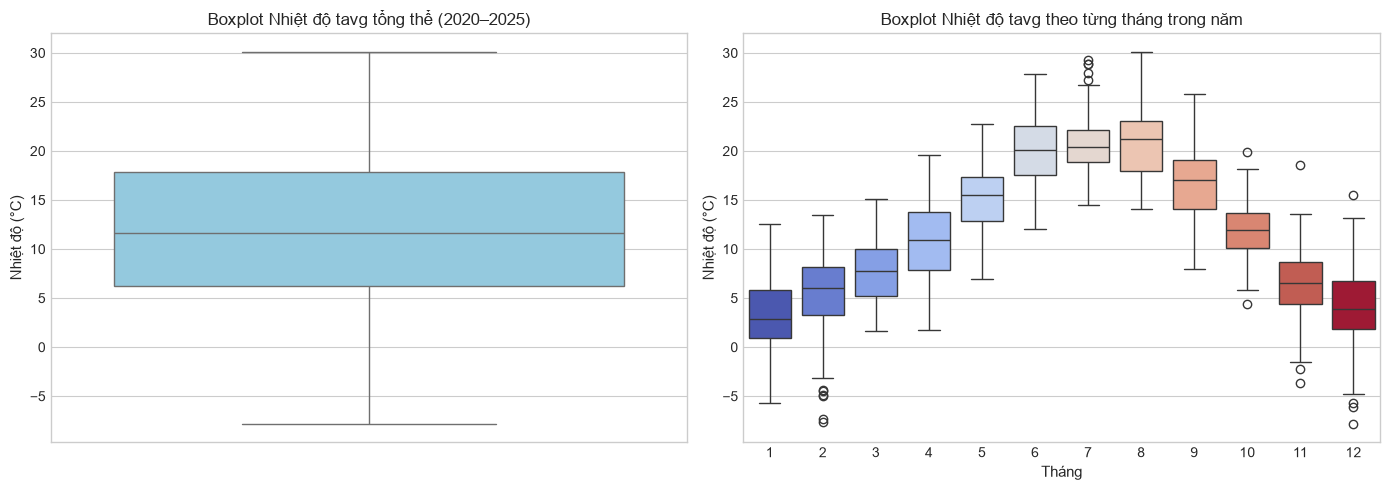


--- BẢNG NGOẠI LAI THEO THÁNG  (2020–2024) ---


,Tháng,Số lượng Outliers,Ngưỡng dưới (LB),Ngưỡng trên (UB),Giá trị cực trị phát hiện
0,2,7,-3.0,15.3,"[-7.6, -7.3, -5.0, -4.9, -4.5, -4.4, -3.1]"
1,7,5,14.1,26.9,"[27.2, 27.9, 28.9, 28.9, 29.3]"
2,10,1,4.3,19.7,[19.9]
3,11,3,-2.1,15.3,"[-3.7, -2.2, 18.6]"
4,12,4,-5.5,14.3,"[-7.8, -6.1, -5.7, 15.5]"


Đã đánh dấu 20 ngày ngoại lai trong 2020–2025 .


In [9]:
tavg_min = df_eda['tavg'].min()
date_min = df_eda['tavg'].idxmin().strftime('%d/%m/%Y')
tavg_max = df_eda['tavg'].max()
date_max = df_eda['tavg'].idxmax().strftime('%d/%m/%Y')

# Thống kê số ngày vượt các ngưỡng cực trị minh họa
days_below_neg5 = (df_eda['tavg'] < -5.0).sum()

print("--- THỐNG KÊ GIÁ TRỊ CỰC TRỊ (2020–2025) ---")
print(f"- Thấp nhất: {tavg_min}°C (ngày {date_min})")
print(f"- Cao nhất: {tavg_max}°C (ngày {date_max})")
print(f"- Số ngày có tavg < -5°C (ngưỡng rét sâu): {days_below_neg5} ngày")

# Vẽ Boxplot tổng thể và Boxplot theo từng tháng
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot tổng thể
sns.boxplot(y=df_eda['tavg'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot Nhiệt độ tavg tổng thể (2020–2025)')
axes[0].set_ylabel('Nhiệt độ (°C)')

# Boxplot theo từng tháng
df_eda['month'] = df_eda.index.month
sns.boxplot(x='month', y='tavg', data=df_eda, hue='month', ax=axes[1], palette='coolwarm', legend=False)
axes[1].set_title('Boxplot Nhiệt độ tavg theo từng tháng trong năm')
axes[1].set_xlabel('Tháng')
axes[1].set_ylabel('Nhiệt độ (°C)')
plt.show()

# Quét ngoại lệ theo quy tắc 1.5*IQR của từng tháng
tr = df_clean[df_clean['split'] == 'train']
bien_thang = {}
for m in range(1, 13):
    ref = tr.loc[tr.index.month == m, 'tavg']
    q1_m, q3_m = ref.quantile(0.25), ref.quantile(0.75)
    iqr_m = q3_m - q1_m
    bien_thang[m] = (q1_m - 1.5 * iqr_m, q3_m + 1.5 * iqr_m)

monthly_outliers = []
for m in range(1, 13):
    lb, ub = bien_thang[m]
    m_series = df_eda[df_eda['month'] == m]['tavg']
    outs = m_series[(m_series < lb) | (m_series > ub)]
    if len(outs) > 0:
        monthly_outliers.append({
            'Tháng': m, 'Số lượng Outliers': len(outs),
            'Ngưỡng dưới (LB)': round(lb, 1), 'Ngưỡng trên (UB)': round(ub, 1),
            'Giá trị cực trị phát hiện': sorted(outs.round(1).tolist())})
print("\n--- BẢNG NGOẠI LAI THEO THÁNG  (2020–2024) ---")
display(pd.DataFrame(monthly_outliers))

thang = df_clean.index.month
lb_all = pd.Series({m: v[0] for m, v in bien_thang.items()}).reindex(thang).values
ub_all = pd.Series({m: v[1] for m, v in bien_thang.items()}).reindex(thang).values
df_clean['co_ngoai_lai_tavg'] = (df_clean['tavg'] < lb_all) | (df_clean['tavg'] > ub_all)
assert len(df_clean) == len(df_raw), "Có dòng bị mất!"
print(f"Đã đánh dấu {int(df_clean.loc[df_clean['split'] != 'test', 'co_ngoai_lai_tavg'].sum())} ngày ngoại lai trong 2020–2025 .")

## 9. Phân tích xu hướng: Chuỗi thời gian & Trung bình trượt

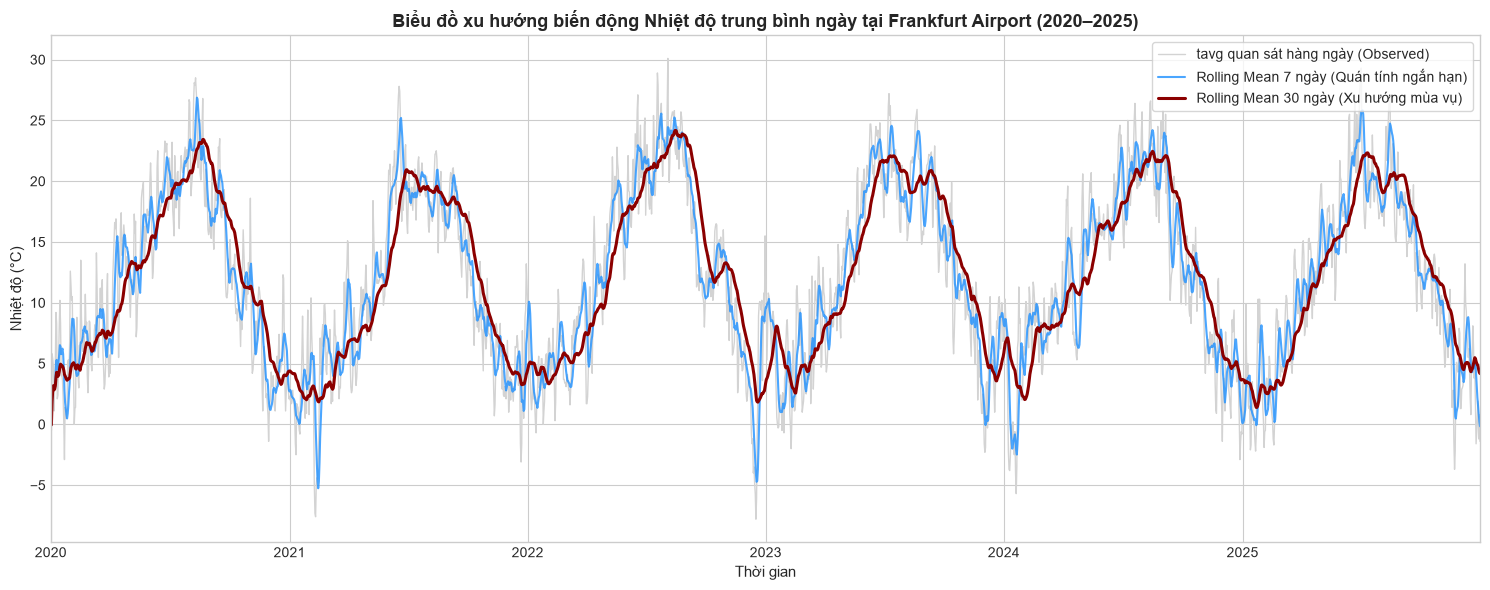

In [10]:
# Đường trung bình trượt 7 ngày và 30 ngày trong giai đoạn 2020-2025
rolling_7 = df_eda['tavg'].rolling(window=7, min_periods=1).mean()
rolling_30 = df_eda['tavg'].rolling(window=30, min_periods=1).mean()

plt.figure(figsize=(15, 6))
plt.plot(df_eda.index, df_eda['tavg'], color='lightgray', linewidth=1, label='tavg quan sát hàng ngày (Observed)')
plt.plot(df_eda.index, rolling_7, color='dodgerblue', linewidth=1.5, alpha=0.8, label='Rolling Mean 7 ngày (Quán tính ngắn hạn)')
plt.plot(df_eda.index, rolling_30, color='darkred', linewidth=2.2, label='Rolling Mean 30 ngày (Xu hướng mùa vụ)')

plt.title('Biểu đồ xu hướng biến động Nhiệt độ trung bình ngày tại Frankfurt Airport (2020–2025)', fontsize=13, fontweight='bold')
plt.xlabel('Thời gian')
plt.ylabel('Nhiệt độ (°C)')
plt.xlim(df_eda.index.min(), df_eda.index.max())
plt.legend(loc='upper right', frameon=True)
plt.show()

## 10. Phân tích tính mùa vụ & Định lượng

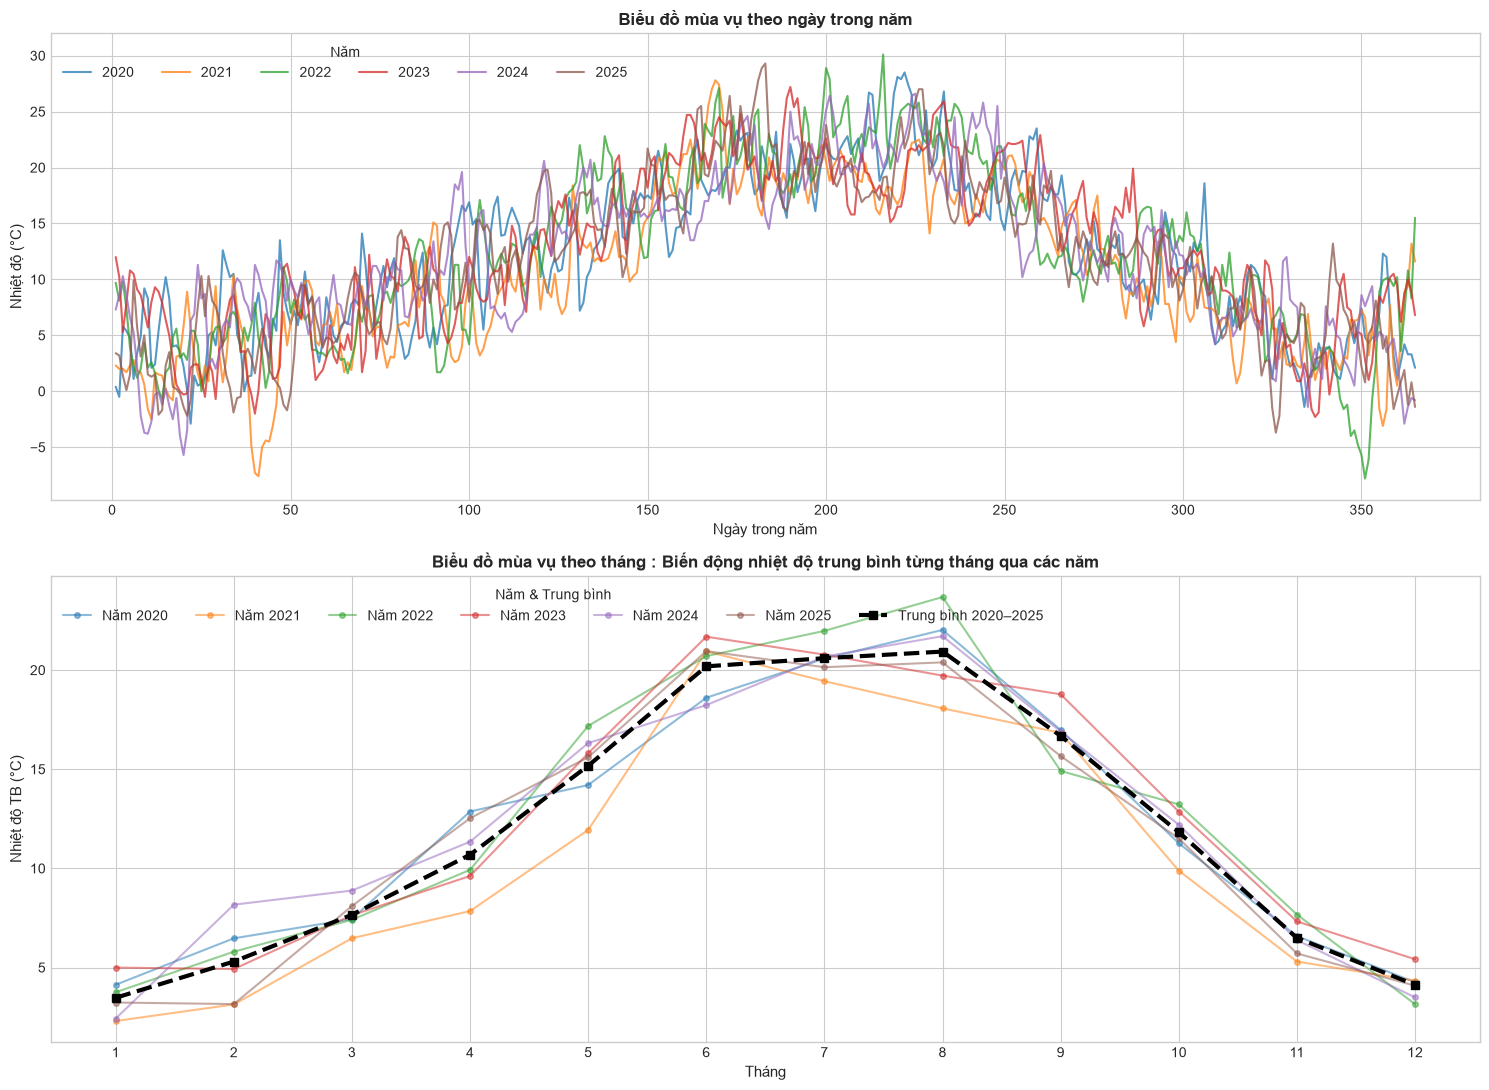

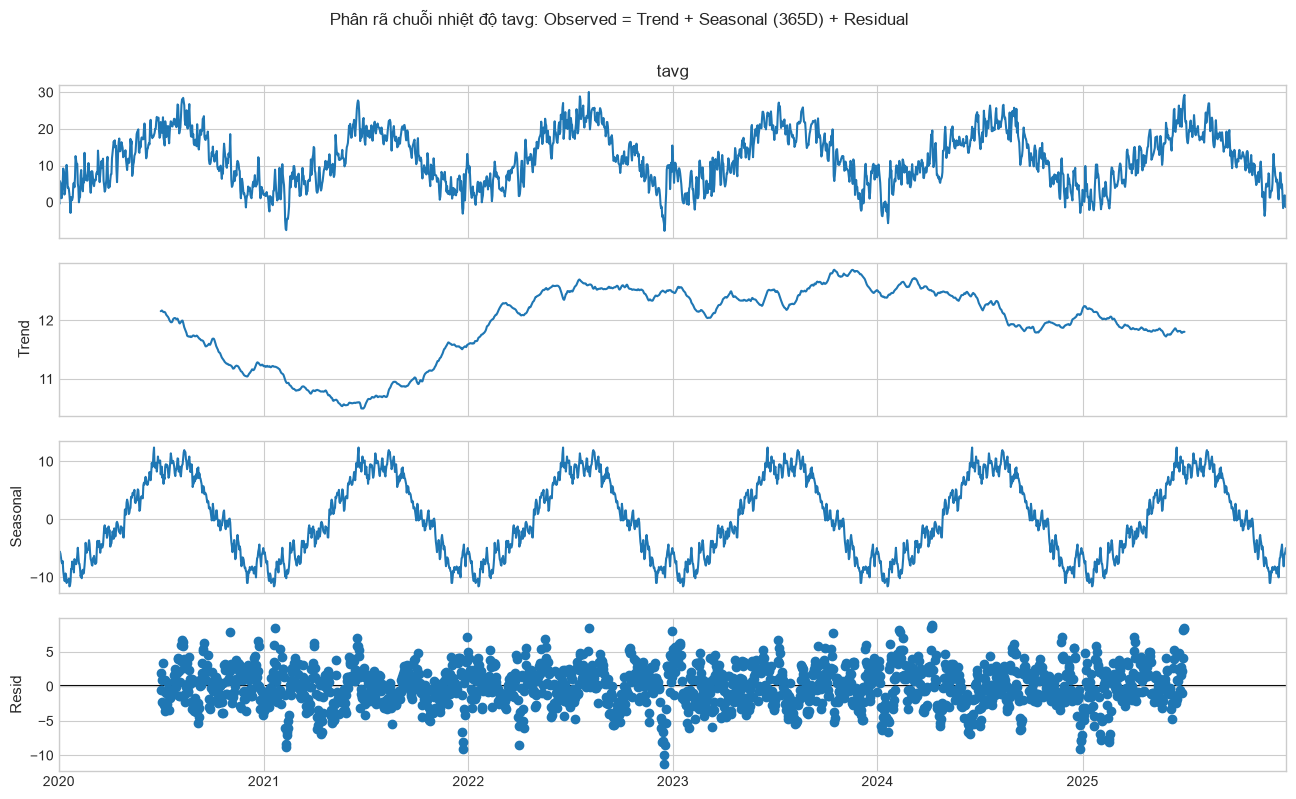

BẢNG 1: ĐẶC TRƯNG NHIỆT ĐỘ THEO THÁNG (2020–2025) 


,Trung_bình,Độ_lệch_chuẩn,Thấp_nhất,Cao_nhất
Tháng,,,,
1,3.48,3.72,-5.7,12.6
2,5.30,3.98,-7.6,13.5
3,7.66,3.15,1.6,15.1
4,10.69,3.92,1.7,19.6
5,15.17,3.26,6.9,22.8
6,20.19,3.27,12.0,27.8
7,20.60,2.77,14.5,29.3
8,20.93,3.45,14.1,30.1
9,16.68,3.63,8.0,25.8



BẢNG 2: BIẾN ĐỘNG NHIỆT ĐỘ THEO NĂM (2020–2025) 


,Trung_bình,Độ_lệch_chuẩn,Thấp_nhất,Cao_nhất
Năm,,,,
2020,12.13,6.96,-2.9,28.5
2021,10.58,7.14,-7.6,27.8
2022,12.49,7.69,-7.8,30.1
2023,12.50,7.09,-2.3,27.2
2024,12.24,7.04,-5.7,26.6
2025,11.80,7.27,-3.7,29.3



- Tháng nóng nhất: Tháng 8 (20.93°C)
- Tháng lạnh nhất: Tháng 1 (3.48°C)
- Biên độ dao động mùa vụ (Seasonal Amplitude): 17.45°C

BẢNG 3: THEO MÙA KHÍ TƯỢNG


,Trung_bình,Độ_lệch_chuẩn
Mùa,,
Đông,4.27,3.96
Xuân,11.18,4.64
Hè,20.58,3.18
Thu,11.67,5.24


In [11]:
df_eda['year'] = df_eda.index.year
df_eda['day_of_year'] = pd.to_datetime('2021-' + df_eda.index.strftime('%m-%d'), errors='coerce').dayofyear

fig, axes = plt.subplots(2, 1, figsize=(15, 11))

# 1. Seasonal Plot theo ngày trong năm (Day of Year 1–365/366)
sns.lineplot(data=df_eda, x='day_of_year', y='tavg', hue='year', palette='tab10', alpha=0.75, linewidth=1.5, ax=axes[0])
axes[0].set_title('Biểu đồ mùa vụ theo ngày trong năm', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ngày trong năm')
axes[0].set_ylabel('Nhiệt độ (°C)')
axes[0].legend(title='Năm', ncol=6, loc='upper left')

# 2. Seasonal Subseries Plot theo từng tháng trong năm (FPP3 - Chương 2)
monthly_yearly = df_eda.groupby(['year', 'month'])['tavg'].mean().unstack(level=0)
for yr in monthly_yearly.columns:
    axes[1].plot(monthly_yearly.index, monthly_yearly[yr], marker='o', markersize=4, alpha=0.5, label=f'Năm {yr}')

overall_monthly_mean = df_eda.groupby('month')['tavg'].mean()
axes[1].plot(overall_monthly_mean.index, overall_monthly_mean.values, color='black', linewidth=3, linestyle='--', marker='s', label='Trung bình 2020–2025')
axes[1].set_title('Biểu đồ mùa vụ theo tháng : Biến động nhiệt độ trung bình từng tháng qua các năm', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tháng')
axes[1].set_ylabel('Nhiệt độ TB (°C)')
axes[1].set_xticks(range(1, 13))
axes[1].legend(title='Năm & Trung bình', ncol=7, loc='upper left')

plt.show()

# 3. Phân rã chuỗi thời gian Additive Decomposition (FPP3 - Chương 3: Chu kỳ 365 ngày)
decomposition = seasonal_decompose(df_eda['tavg'], model='additive', period=365)
phan_du = decomposition.resid.dropna()
mua_vu = decomposition.seasonal.loc[phan_du.index]
do_manh_mua_vu = max(0, 1 - phan_du.var() / (phan_du + mua_vu).var())
fig_decomp = decomposition.plot()
fig_decomp.set_size_inches(14, 8)
fig_decomp.suptitle('Phân rã chuỗi nhiệt độ tavg: Observed = Trend + Seasonal (365D) + Residual', y=1.02)
plt.show()

# 4. Định lượng số liệu chi tiết phục vụ trả lời RQ1
monthly_table = df_eda.groupby('month')['tavg'].agg(
    Trung_bình='mean',
    Độ_lệch_chuẩn='std',
    Thấp_nhất='min',
    Cao_nhất='max'
).round(2)
monthly_table.index.name = 'Tháng'

yearly_table = df_eda.groupby('year')['tavg'].agg(
    Trung_bình='mean',
    Độ_lệch_chuẩn='std',
    Thấp_nhất='min',
    Cao_nhất='max'
).round(2)
yearly_table.index.name = 'Năm'

hottest_m = monthly_table['Trung_bình'].idxmax()
coldest_m = monthly_table['Trung_bình'].idxmin()
seasonal_amp = monthly_table.loc[hottest_m, 'Trung_bình'] - monthly_table.loc[coldest_m, 'Trung_bình']

print("BẢNG 1: ĐẶC TRƯNG NHIỆT ĐỘ THEO THÁNG (2020–2025) ")
display(monthly_table)

print("\nBẢNG 2: BIẾN ĐỘNG NHIỆT ĐỘ THEO NĂM (2020–2025) ")
display(yearly_table)

print(f"\n- Tháng nóng nhất: Tháng {hottest_m} ({monthly_table.loc[hottest_m, 'Trung_bình']}°C)")
print(f"- Tháng lạnh nhất: Tháng {coldest_m} ({monthly_table.loc[coldest_m, 'Trung_bình']}°C)")
print(f"- Biên độ dao động mùa vụ (Seasonal Amplitude): {seasonal_amp:.2f}°C")

mua = {12: 'Đông', 1: 'Đông', 2: 'Đông', 3: 'Xuân', 4: 'Xuân', 5: 'Xuân',
       6: 'Hè', 7: 'Hè', 8: 'Hè', 9: 'Thu', 10: 'Thu', 11: 'Thu'}
bang_mua = (df_eda.groupby(df_eda.index.month.map(mua))['tavg']
            .agg(Trung_bình='mean', Độ_lệch_chuẩn='std').round(2).loc[['Đông', 'Xuân', 'Hè', 'Thu']])
bang_mua.index.name = 'Mùa'
print("\nBẢNG 3: THEO MÙA KHÍ TƯỢNG"); display(bang_mua)

## 11. Đợt nóng (RQ1): tmax > 30°C, từ 3 ngày liên tiếp

--- DANH SÁCH CÁC ĐỢT NÓNG (2020–2025) ---


,bat_dau,ket_thuc,so_ngay,tmax_cao_nhat
0,2020-07-30,2020-08-01,3,35.3
1,2020-08-06,2020-08-12,7,37.5
2,2020-09-14,2020-09-16,3,32.7
3,2021-06-15,2021-06-19,5,34.8
4,2022-06-17,2022-06-19,3,36.2
5,2022-07-18,2022-07-20,3,38.4
6,2022-08-02,2022-08-04,3,38.4
7,2022-08-08,2022-08-14,7,33.2
8,2022-08-22,2022-08-26,5,33.0
9,2023-06-09,2023-06-11,3,31.4



BẢNG 4: ĐỢT NÓNG THEO THÁNG


,ngay_nong,ngay_trong_dot,so_dot,do_dai_tb
Tháng,,,,
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0
5,3.0,0.0,0.0,0.0
6,33.0,19.0,5.0,4.2
7,30.0,12.0,3.0,3.7
8,50.0,31.0,6.0,5.0
9,11.0,6.0,2.0,3.0



BẢNG 5: ĐỢT NÓNG THEO NĂM


,ngay_nong,ngay_trong_dot,so_dot,do_dai_max
Năm,,,,
2020,19.0,13.0,3.0,7.0
2021,7.0,5.0,1.0,5.0
2022,37.0,21.0,5.0,7.0
2023,21.0,16.0,4.0,5.0
2024,21.0,4.0,1.0,4.0
2025,22.0,9.0,2.0,5.0



H1: 113/127 ngày nóng (89.0%) rơi vào tháng 6–8; 16 đợt nóng, đợt dài nhất 7 ngày. 


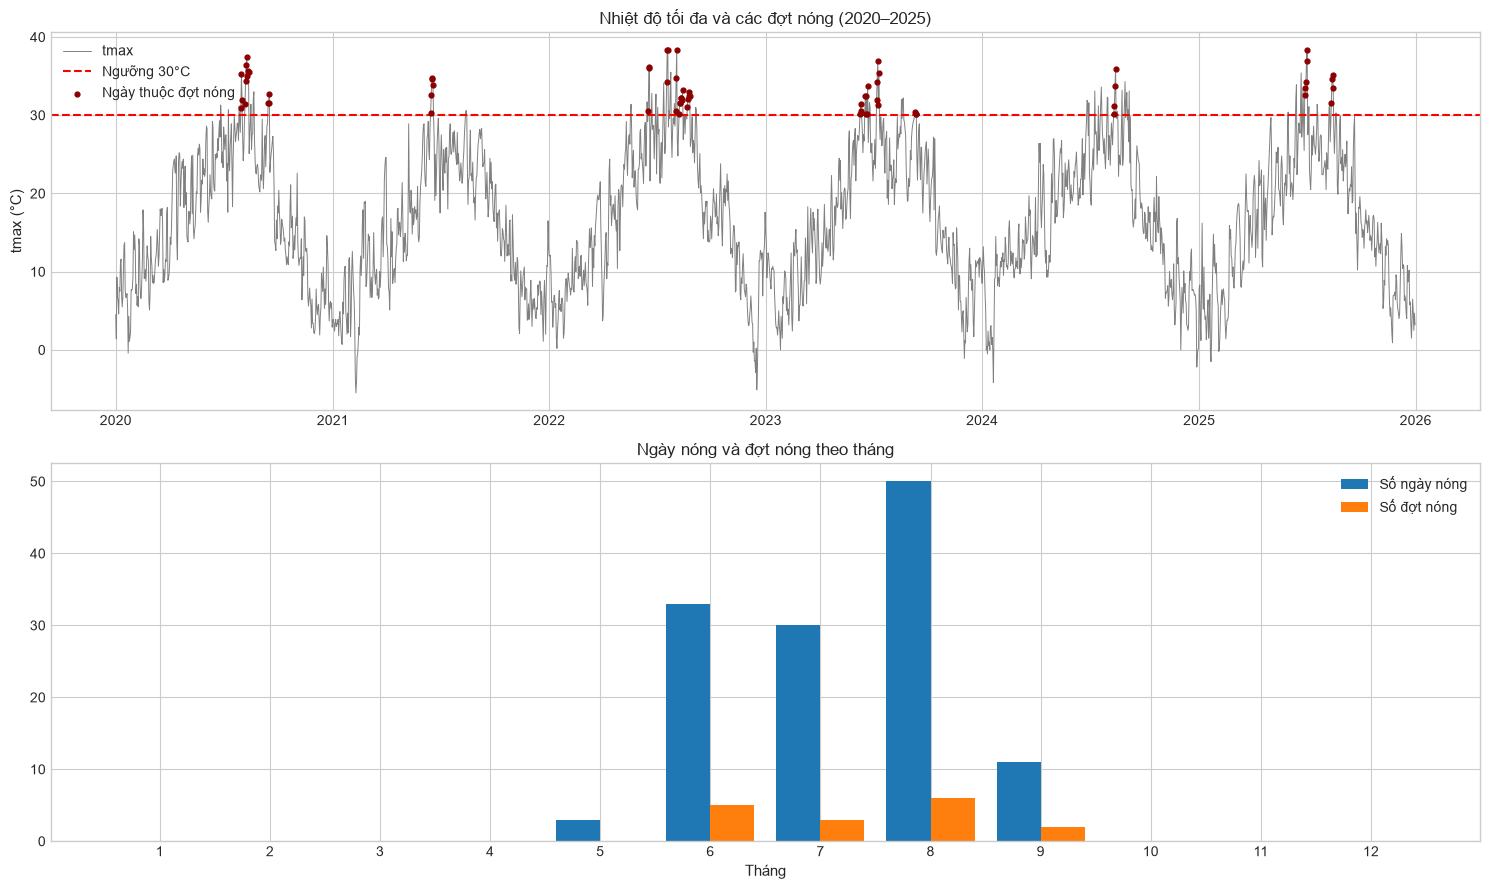

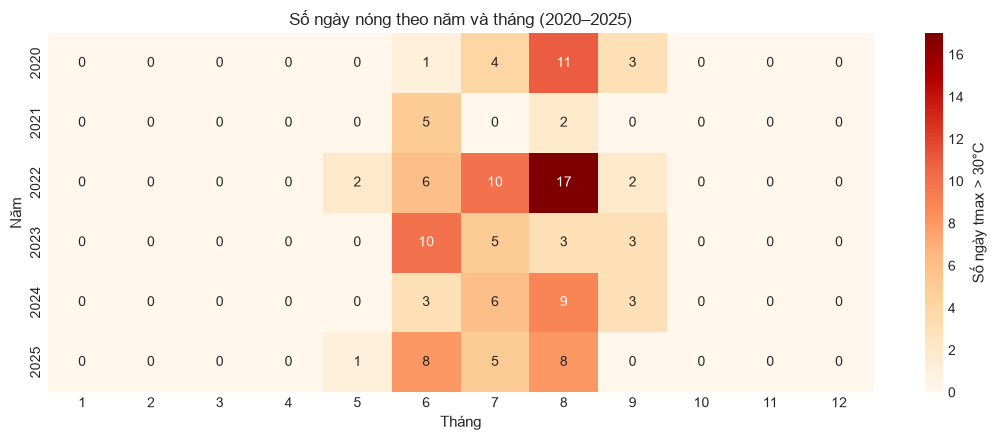


BẢNG 6: ĐỘ NHẠY THEO NGƯỠNG


,Ngưỡng tmax,Số ngày nóng,Số đợt (>=3 ngày),Ngày nóng tháng 6–8 (%)
0,> 28°C,236,29,85.2
1,> 30°C,127,16,89.0
2,> 32°C,62,6,95.2


In [12]:
NGUONG, SO_NGAY_TOI_THIEU = 30, 3

def phat_hien_dot_nong(tmax, nguong=NGUONG, so_ngay=SO_NGAY_TOI_THIEU):
    nong = tmax > nguong
    nhom = (nong != nong.shift()).cumsum()
    do_dai = nong.groupby(nhom).transform('sum')
    return nong, nong & (do_dai >= so_ngay), nhom

nong, trong_dot, nhom = phat_hien_dot_nong(df_eda['tmax'])
df_eda['ngay_nong'] = nong
df_eda['trong_dot_nong'] = trong_dot
df_eda['ma_dot'] = np.where(trong_dot, nhom, np.nan)

dot = (df_eda.dropna(subset=['ma_dot']).groupby('ma_dot')
       .agg(bat_dau=('tmax', lambda s: s.index.min()), ket_thuc=('tmax', lambda s: s.index.max()),
            so_ngay=('tmax', 'size'), tmax_cao_nhat=('tmax', 'max')).reset_index(drop=True))
print("--- DANH SÁCH CÁC ĐỢT NÓNG (2020–2025) ---"); display(dot)

dot['thang'] = dot['bat_dau'].dt.month     # đợt vắt qua hai tháng tính theo tháng bắt đầu
dot['nam'] = dot['bat_dau'].dt.year
theo_thang = pd.DataFrame({
    'ngay_nong': df_eda.groupby(df_eda.index.month)['ngay_nong'].sum(),
    'ngay_trong_dot': df_eda.groupby(df_eda.index.month)['trong_dot_nong'].sum(),
    'so_dot': dot.groupby('thang').size(),
    'do_dai_tb': dot.groupby('thang')['so_ngay'].mean().round(1)}).reindex(range(1, 13)).fillna(0)
theo_nam = pd.DataFrame({
    'ngay_nong': df_eda.groupby(df_eda.index.year)['ngay_nong'].sum(),
    'ngay_trong_dot': df_eda.groupby(df_eda.index.year)['trong_dot_nong'].sum(),
    'so_dot': dot.groupby('nam').size(),
    'do_dai_max': dot.groupby('nam')['so_ngay'].max()}).fillna(0)
theo_thang.index.name, theo_nam.index.name = 'Tháng', 'Năm'
print("\nBẢNG 4: ĐỢT NÓNG THEO THÁNG"); display(theo_thang.astype(float).round(1))
print("\nBẢNG 5: ĐỢT NÓNG THEO NĂM"); display(theo_nam.astype(float).round(1))

tong_ngay_nong = int(df_eda['ngay_nong'].sum())
ngay_nong_he = int(df_eda.loc[df_eda.index.month.isin([6, 7, 8]), 'ngay_nong'].sum())
ty_le_he = 100 * ngay_nong_he / tong_ngay_nong
print(f"\nH1: {ngay_nong_he}/{tong_ngay_nong} ngày nóng ({ty_le_he:.1f}%) rơi vào tháng 6–8; "
      f"{len(dot)} đợt nóng, đợt dài nhất {int(dot['so_ngay'].max())} ngày. ")

# Biểu đồ 1–2: tmax và các đợt nóng; ngày/đợt nóng theo tháng
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
axes[0].plot(df_eda.index, df_eda['tmax'], color='gray', linewidth=0.7, label='tmax')
axes[0].axhline(NGUONG, color='red', linestyle='--', label=f'Ngưỡng {NGUONG}°C')
axes[0].scatter(df_eda.index[df_eda['trong_dot_nong']], df_eda.loc[df_eda['trong_dot_nong'], 'tmax'],
                color='darkred', s=12, zorder=3, label='Ngày thuộc đợt nóng')
axes[0].set_title('Nhiệt độ tối đa và các đợt nóng (2020–2025)'); axes[0].set_ylabel('tmax (°C)'); axes[0].legend()
x, w = np.arange(1, 13), 0.4
axes[1].bar(x - w/2, theo_thang['ngay_nong'], width=w, label='Số ngày nóng')
axes[1].bar(x + w/2, theo_thang['so_dot'], width=w, label='Số đợt nóng')
axes[1].set_xticks(x); axes[1].set_xlabel('Tháng'); axes[1].set_title('Ngày nóng và đợt nóng theo tháng'); axes[1].legend()
plt.show()

# Biểu đồ 3: bản đồ nhiệt năm x tháng (gọn cho slide)
pivot = (df_eda.assign(nam=df_eda.index.year, thang=df_eda.index.month)
         .assign(ngay_nong=lambda d: d['ngay_nong'].astype(int))
         .pivot_table(index='nam', columns='thang', values='ngay_nong', aggfunc='sum')
         .reindex(columns=range(1, 13), fill_value=0).fillna(0).astype(int))
plt.figure(figsize=(11, 4.5))
sns.heatmap(pivot, annot=True, fmt='d', cmap='OrRd', cbar_kws={'label': 'Số ngày tmax > 30°C'})
plt.title('Số ngày nóng theo năm và tháng (2020–2025)'); plt.xlabel('Tháng'); plt.ylabel('Năm')
plt.show()

# Độ nhạy theo ngưỡng (ghi vào phần hạn chế của báo cáo)
hang = []
for ng in (28, 30, 32):
    n, t, nh = phat_hien_dot_nong(df_eda['tmax'], nguong=ng)
    hang.append({'Ngưỡng tmax': f'> {ng}°C', 'Số ngày nóng': int(n.sum()),
                 'Số đợt (>=3 ngày)': int(nh[t].nunique()),
                 'Ngày nóng tháng 6–8 (%)': round(100 * n[n.index.month.isin([6, 7, 8])].sum() / n.sum(), 1)})
print("\nBẢNG 6: ĐỘ NHẠY THEO NGƯỠNG"); display(pd.DataFrame(hang))

## 12. Độ lệch so với trung bình tháng

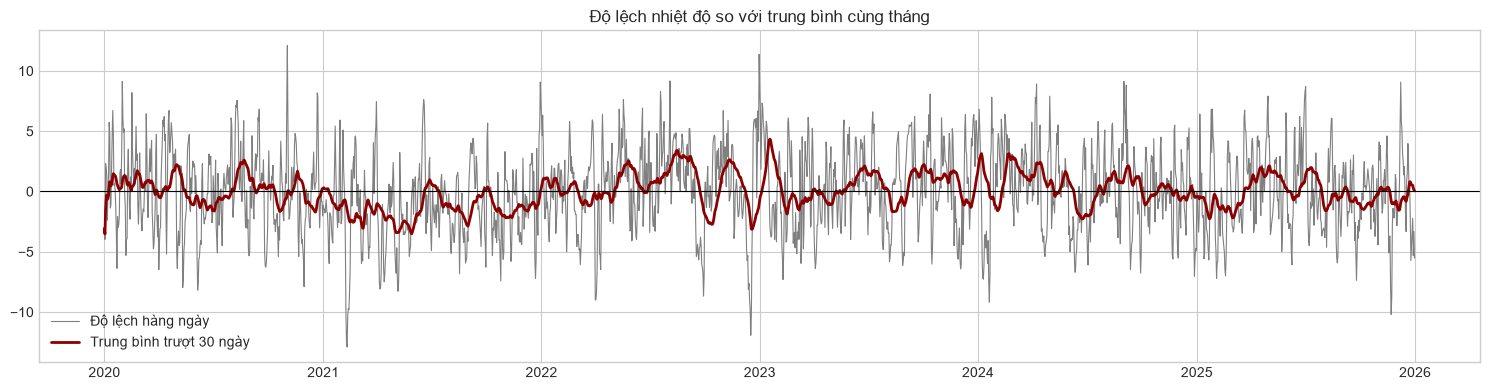

      Độ lệch TB theo năm (°C)
date                          
2020                      0.18
2021                     -1.39
2022                      0.53
2023                      0.54
2024                      0.29
2025                     -0.16


In [13]:
df_eda['month'] = df_eda.index.month
df_eda['do_lech'] = df_eda['tavg'] - df_eda.groupby('month')['tavg'].transform('mean')
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(df_eda.index, df_eda['do_lech'], color='gray', linewidth=0.8, label='Độ lệch hàng ngày')
ax.plot(df_eda.index, df_eda['do_lech'].rolling(30, min_periods=1).mean(),
        color='darkred', linewidth=2, label='Trung bình trượt 30 ngày')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Độ lệch nhiệt độ so với trung bình cùng tháng')
ax.legend()
plt.show()
print(df_eda.groupby(df_eda.index.year)['do_lech'].mean().round(2).to_frame('Độ lệch TB theo năm (°C)'))

## 13. Biểu đồ ACF & PACF

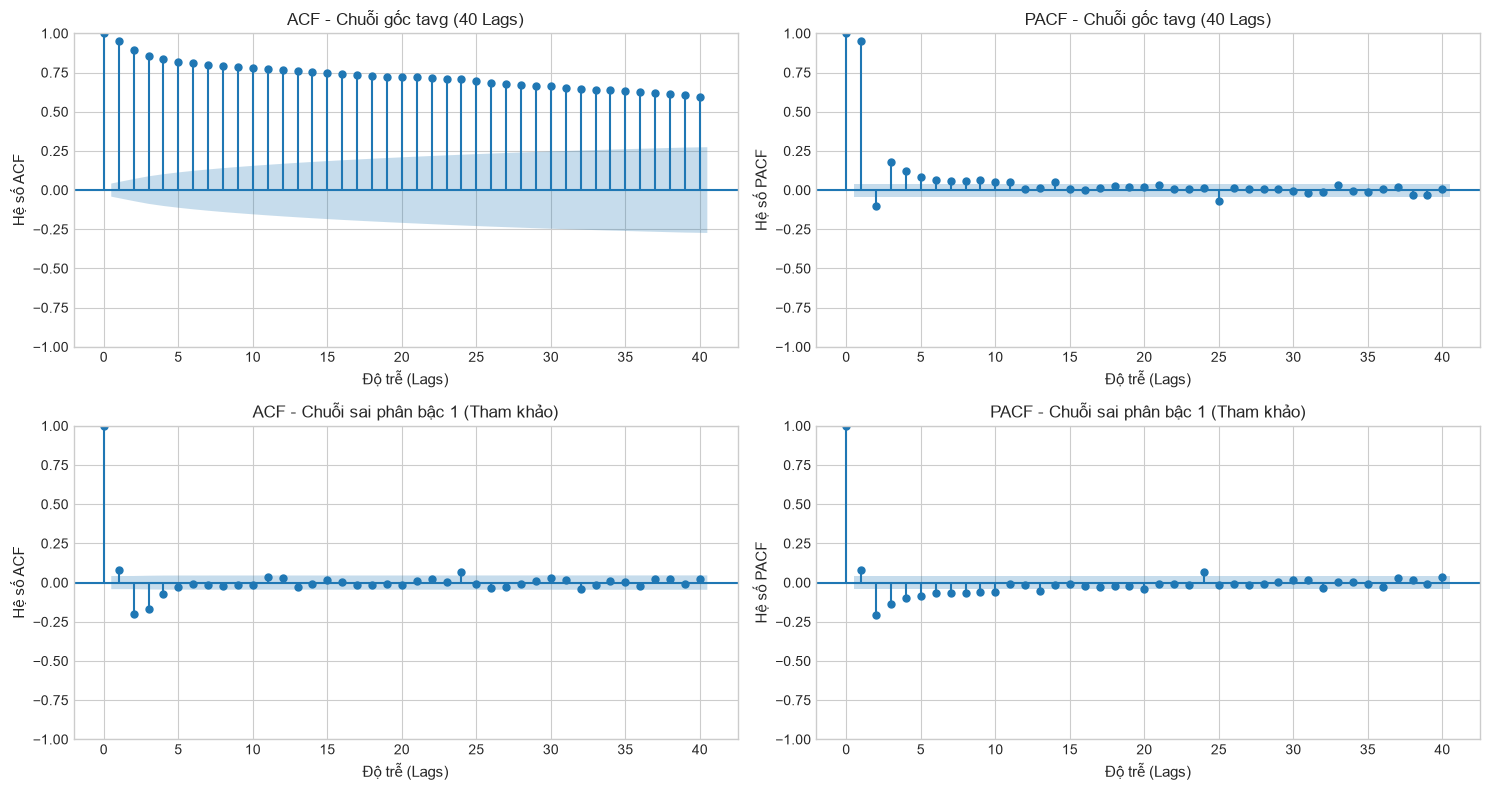

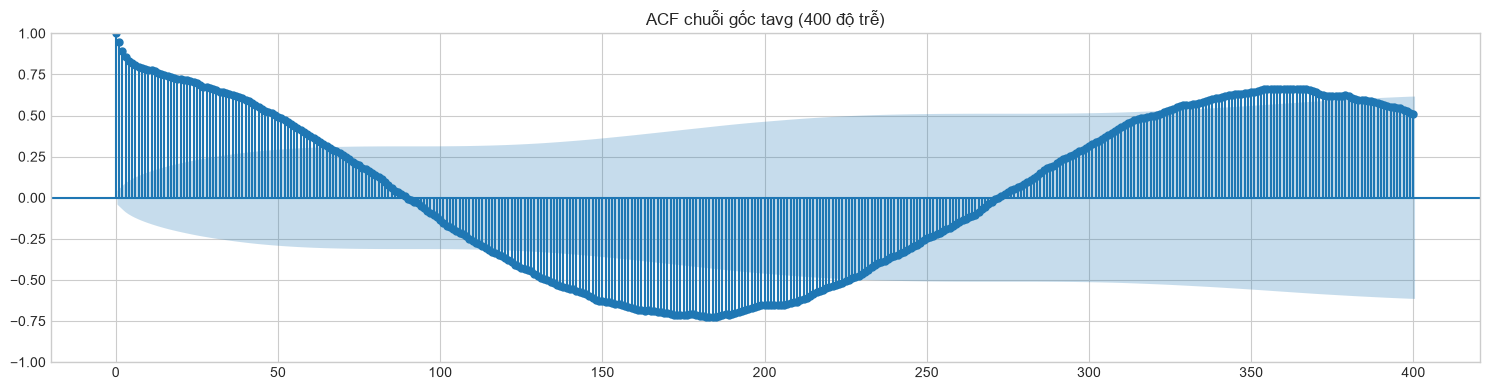

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

# Hàng 1: Chuỗi gốc
plot_acf(df_eda['tavg'], lags=40, ax=axes[0, 0], title='ACF - Chuỗi gốc tavg (40 Lags)')
axes[0, 0].set_xlabel('Độ trễ (Lags)')
axes[0, 0].set_ylabel('Hệ số ACF')

plot_pacf(df_eda['tavg'], lags=40, method='ywm', ax=axes[0, 1], title='PACF - Chuỗi gốc tavg (40 Lags)')
axes[0, 1].set_xlabel('Độ trễ (Lags)')
axes[0, 1].set_ylabel('Hệ số PACF')

# Hàng 2: Chuỗi sai phân bậc 1
diff_1 = df_eda['tavg'].diff().dropna()
plot_acf(diff_1, lags=40, ax=axes[1, 0], title='ACF - Chuỗi sai phân bậc 1 (Tham khảo)')
axes[1, 0].set_xlabel('Độ trễ (Lags)')
axes[1, 0].set_ylabel('Hệ số ACF')

plot_pacf(diff_1, lags=40, method='ywm', ax=axes[1, 1], title='PACF - Chuỗi sai phân bậc 1 (Tham khảo)')
axes[1, 1].set_xlabel('Độ trễ (Lags)')
axes[1, 1].set_ylabel('Hệ số PACF')

plt.show()

fig, ax = plt.subplots(figsize=(15, 4))
plot_acf(df_eda['tavg'], lags=400, ax=ax, title='ACF chuỗi gốc tavg (400 độ trễ)')
plt.show()

## 14. Xuất file

In [15]:
cot_xuat = ['tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wspd', 'wpgt', 'pres', 'tsun', 'split', 'co_ngoai_lai_tavg']
weather_clean = df_clean[cot_xuat]
assert len(weather_clean) == len(df_raw) and weather_clean['tavg'].notna().all()
weather_clean.to_csv(CLEAN_DATA_PATH, index=True, date_format='%Y-%m-%d')

print(f"- Đã lưu 'weather_clean.csv' vào {PROCESSED_DATA_DIR}: {weather_clean.shape[0]} dòng x {weather_clean.shape[1]} cột, ")
print(f"  {weather_clean.index.min():%Y-%m-%d} -> {weather_clean.index.max():%Y-%m-%d}")

- Đã lưu 'weather_clean.csv' vào /Users/tuong/Documents/MONHOCDAIHOC/năm IV-HK1 (2026-2027)/PP Nghiên Cứu KHDL/Frankfurt_Temperature_Forecasting/data/processed: 2373 dòng x 11 cột, 
  2020-01-01 -> 2026-06-30
